## Load the libraries

In [1]:
import torch 
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.optim as optim
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import timm
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Load dataset

In [2]:
real_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\original_sequences\youtube\c23\videos"
)

fake_dir = Path(
    r"D:\Projects\Deepfake detection\datasets\videos\manipulated_sequences\Deepfakes\c23\videos"
)

real_videos = list(real_dir.glob("*.mp4"))
fake_videos = list(fake_dir.glob("*.mp4"))

print("Real videos:", len(real_videos))
print("Fake videos:", len(fake_videos))

print("\nSample real video:", real_videos[0].name if real_videos else "None")
print("Sample fake video:", fake_videos[0].name if fake_videos else "None")

Real videos: 200
Fake videos: 200

Sample real video: 004.mp4
Sample fake video: 004_982.mp4


Video opened: True
Total frames: 309
FPS: 25.0


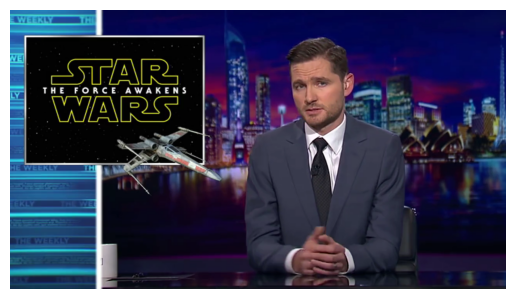

In [3]:
video_path = str(real_videos[0])

cap = cv.VideoCapture(video_path)

print("Video opened:", cap.isOpened())
print("Total frames:", int(cap.get(cv.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv.CAP_PROP_FPS))

ret, frame = cap.read()

if ret:
    frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    plt.imshow(frame)
    plt.axis("off")
    plt.show()
else:
    print("Could not read a frame.")

cap.release()

In [4]:
def extract_frames(video_path, num_frames=16):
    cap = cv.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

    if not cap.isOpened() or total_frames == 0:
        cap.release()
        raise ValueError(f"Cannot read video: {video_path}")

    indices = np.linspace(
        0, total_frames - 1, num_frames, dtype=int
    )

    frames = []

    for idx in indices:
        cap.set(cv.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()

        if ret:
            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frames.append(frame)

    cap.release()

    return frames

sample_frames = extract_frames(real_videos[0])

print("Frames extracted:", len(sample_frames))
print("Frame shape:", sample_frames[0].shape if sample_frames else None)

Frames extracted: 16
Frame shape: (720, 1280, 3)


In [5]:
IMG_SIZE = 299

transform = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
    ]
)

frame_tensor = transform(sample_frames[0])

print("Transformed frame shape:", frame_tensor.shape)
print("Data type:", frame_tensor.dtype)

Transformed frame shape: torch.Size([3, 299, 299])
Data type: torch.float32


In [6]:
class DeepfakeVideoDataset(Dataset):
    def __init__(self, real_videos, fake_videos, transform, num_frames=16):
        self.video_paths = (
            [(path, 0) for path in real_videos] +
            [(path, 1) for path in fake_videos]
        )
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.video_paths)

    def __getitem__(self, idx):
        video_path, label = self.video_paths[idx]

        cap = cv.VideoCapture(str(video_path))
        total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

        if not cap.isOpened() or total_frames == 0:
            cap.release()
            raise RuntimeError(f"Cannot read video: {video_path}")

        indices = np.linspace(
            0, total_frames - 1, self.num_frames, dtype=int
        )

        frames = []

        for frame_idx in indices:
            cap.set(cv.CAP_PROP_POS_FRAMES, int(frame_idx))
            ret, frame = cap.read()

            if not ret:
                cap.release()
                raise RuntimeError(
                    f"Failed to read frame {frame_idx} from {video_path}"
                )

            frame = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
            frame = self.transform(frame)
            frames.append(frame)

        cap.release()

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [7]:
video_dataset = DeepfakeVideoDataset(real_videos, fake_videos, transform)
print("Dataset length:", len(video_dataset))

Dataset length: 400


In [8]:
frames, label = video_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

Frames shape: torch.Size([16, 3, 299, 299])
Label: tensor(0)


In [9]:
real_names = [p.stem for p in real_videos]
fake_names = [p.stem for p in fake_videos]

print("Sample real names:", real_names[:10])
print("Sample fake names:", fake_names[:10])

Sample real names: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044']
Sample fake names: ['004_982', '008_990', '009_027', '015_919', '027_009', '032_944', '033_097', '035_036', '036_035', '044_945']


In [10]:
real_ids = {p.stem for p in real_videos}
fake_source_ids = set()
for path in fake_videos:
    parts = path.stem.split("_")
    fake_source_ids.update(parts)

print("Unique real source IDs:", len(real_ids))
print("Unique IDs in fake filenames:", len(fake_source_ids))
print("Overlapping IDs:", len(real_ids & fake_source_ids))
print("Sample overlapping IDs:", sorted(real_ids & fake_source_ids)[:20])

Unique real source IDs: 200
Unique IDs in fake filenames: 200
Overlapping IDs: 200
Sample overlapping IDs: ['004', '008', '009', '015', '027', '032', '033', '035', '036', '044', '046', '054', '055', '060', '062', '066', '071', '088', '096', '097']


In [11]:
for real_path in real_videos[:10]:
    source_id = real_path.stem

    matches = [
        p.name for p in fake_videos
        if source_id in p.stem.split("_")
    ]

    print(f"Real: {real_path.name} -> Fake: {matches}")

Real: 004.mp4 -> Fake: ['004_982.mp4', '982_004.mp4']
Real: 008.mp4 -> Fake: ['008_990.mp4', '990_008.mp4']
Real: 009.mp4 -> Fake: ['009_027.mp4', '027_009.mp4']
Real: 015.mp4 -> Fake: ['015_919.mp4', '919_015.mp4']
Real: 027.mp4 -> Fake: ['009_027.mp4', '027_009.mp4']
Real: 032.mp4 -> Fake: ['032_944.mp4', '944_032.mp4']
Real: 033.mp4 -> Fake: ['033_097.mp4', '097_033.mp4']
Real: 035.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 036.mp4 -> Fake: ['035_036.mp4', '036_035.mp4']
Real: 044.mp4 -> Fake: ['044_945.mp4', '945_044.mp4']


In [12]:
from collections import defaultdict

# Each source ID is a node.
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

# Include every real-video ID.
for path in real_videos:
    find(path.stem)

# Connect the two IDs appearing in each fake filename.
for path in fake_videos:
    ids = path.stem.split("_")

    if len(ids) == 2:
        union(ids[0], ids[1])

# Group real videos by connected component.
groups = defaultdict(list)

for path in real_videos:
    groups[find(path.stem)].append(path.stem)

print("Number of source groups:", len(groups))
print("Sample groups:", list(groups.values())[:10])

Number of source groups: 100
Sample groups: [['004', '982'], ['008', '990'], ['009', '027'], ['015', '919'], ['032', '944'], ['033', '097'], ['035', '036'], ['044', '945'], ['046', '904'], ['054', '071']]


In [13]:
group_list = list(groups.values())

print("Total groups:", len(group_list))
print("Largest group size:", max(len(g) for g in group_list))
print("Group sizes:", sorted([len(g) for g in group_list], reverse=True))

Total groups: 100
Largest group size: 2
Group sizes: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [14]:
import random

random.seed(42)

group_list = list(groups.values())
random.shuffle(group_list)

train_groups = group_list[:70]
val_groups = group_list[70:85]
test_groups = group_list[85:]

print("Train groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

Train groups: 70
Validation groups: 15
Test groups: 15


In [15]:
train_ids = {x for group in train_groups for x in group}
val_ids = {x for group in val_groups for x in group}
test_ids = {x for group in test_groups for x in group}

print("Train source IDs:", len(train_ids))
print("Validation source IDs:", len(val_ids))
print("Test source IDs:", len(test_ids))

print("Train/validation overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))

Train source IDs: 140
Validation source IDs: 30
Test source IDs: 30
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


In [16]:
def assign_videos(real_videos, fake_videos, source_ids):
    selected = []

    # Add real videos
    for path in real_videos:
        if path.stem in source_ids:
            selected.append((path, 0))

    # Add fake videos only when both source IDs belong to this split
    for path in fake_videos:
        ids = path.stem.split("_")

        if len(ids) == 2 and all(x in source_ids for x in ids):
            selected.append((path, 1))

    return selected


train_samples = assign_videos(real_videos, fake_videos, train_ids)
val_samples = assign_videos(real_videos, fake_videos, val_ids)
test_samples = assign_videos(real_videos, fake_videos, test_ids)


def show_counts(name, samples):
    real_count = sum(label == 0 for _, label in samples)
    fake_count = sum(label == 1 for _, label in samples)

    print(f"{name}: {len(samples)} videos | Real: {real_count} | Fake: {fake_count}")


show_counts("Train", train_samples)
show_counts("Validation", val_samples)
show_counts("Test", test_samples)

Train: 280 videos | Real: 140 | Fake: 140
Validation: 60 videos | Real: 30 | Fake: 30
Test: 60 videos | Real: 30 | Fake: 30


In [17]:
class DeepfakeVideoDatasetFromSamples(Dataset):
    def __init__(self, samples, transform, num_frames=16):
        self.samples = samples
        self.transform = transform
        self.num_frames = num_frames

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        video_path, label = self.samples[idx]

        frames = extract_frames(video_path, self.num_frames)

        frames = [
            self.transform(frame)
            for frame in frames
        ]

        frames = torch.stack(frames)

        return frames, torch.tensor(label, dtype=torch.long)

In [18]:
train_dataset = DeepfakeVideoDatasetFromSamples(
    train_samples, transform, num_frames=16
)

val_dataset = DeepfakeVideoDatasetFromSamples(
    val_samples, transform, num_frames=16
)

test_dataset = DeepfakeVideoDatasetFromSamples(
    test_samples, transform, num_frames=16
)

In [19]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

frames, label = train_dataset[0]
print("Frames shape:", frames.shape)
print("Label:", label)

280
60
60


Frames shape: torch.Size([16, 3, 299, 299])
Label: tensor(0)


In [20]:
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)

## Model Training

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [22]:
xception = timm.create_model("legacy_xception", pretrained=True, num_classes=2)
xception = xception.to(device)

print("Device: ", device)
print("Model loaded: ", type(xception).__name__)
print("Classifier: ", xception.fc)

Device:  cuda
Model loaded:  Xception
Classifier:  Linear(in_features=2048, out_features=2, bias=True)


In [23]:
xception.eval()

dummy_frames = torch.randn(2, 3, 299, 299).to(device)

with torch.no_grad():
    outputs = xception(dummy_frames)

print("Input shape:", dummy_frames.shape)
print("Output shape:", outputs.shape)
print("Output:", outputs)

Input shape: torch.Size([2, 3, 299, 299])
Output shape: torch.Size([2, 2])
Output: tensor([[0.2744, 0.1199],
        [0.2233, 0.1505]], device='cuda:0')


In [24]:
videos, labels = next(iter(train_loader))

print("Video shape:", videos.shape)
print("Labels:", labels)

Video shape: torch.Size([2, 16, 3, 299, 299])
Labels: tensor([1, 0])


In [25]:
xception_features = nn.Sequential(*list(xception.children())[:-1])

In [26]:
for param in xception_features.parameters():
    param.requires_grad = False

xception_features.eval()
print(xception_features)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
  (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU(inplace=True)
  (6): Block(
    (skip): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
    (skipbn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (rep): Sequential(
      (0): SeparableConv2d(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
        (pointwise): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
      )
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): SeparableConv2d

In [27]:
xception_features.eval()

with torch.no_grad():
    batch_size, num_frames, channels, height, width = videos.shape

    frames = videos.reshape(
        batch_size * num_frames,
        channels, height, width
    ).to(device)

    features = xception_features(frames)

    features = features.reshape(
        batch_size, num_frames, -1
    )

print("Feature shape:", features.shape)

Feature shape: torch.Size([2, 16, 2048])


In [33]:
class VideoClassifier(nn.Module):
    def __init__(self, hidden_size=128):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=2048,
            hidden_size=hidden_size,
            batch_first=True,
        )
        self.classifer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        out = self.classifer(hn[-1])
        return out.squeeze(1)

In [34]:
video_model = VideoClassifier(hidden_size=128).to(device)

In [35]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(
    [
        {
            "params": video_model.lstm.parameters(),
        },
        {
            "params": video_model.classifer.parameters(),
        }
    ],
    lr = 0.001
)

In [36]:
videos, labels = next(iter(train_loader))

videos = videos.to(device)
labels = labels.float().to(device)

print("Videos:", videos.shape)
print("Labels:", labels)

Videos: torch.Size([2, 16, 3, 299, 299])
Labels: tensor([1., 1.], device='cuda:0')


In [37]:
xception_features.eval()
video_model.train()

batch_size, num_frames, channels, height, width = videos.shape

frames = videos.reshape(
    batch_size * num_frames, channels, height, width
)

with torch.no_grad():
    features = xception_features(frames)

features = features.reshape(batch_size, num_frames, -1)

optimizer.zero_grad()

outputs = video_model(features)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

print("Feature shape:", features.shape)
print("Outputs:", outputs)
print("Loss:", loss.item())

Feature shape: torch.Size([2, 16, 2048])
Outputs: tensor([0.1124, 0.0784], device='cuda:0', grad_fn=<SqueezeBackward1>)
Loss: 0.6466141939163208


In [38]:
probabilities = torch.sigmoid(outputs)

predictions = (probabilities >= 0.5).int()

print("Probabilities:", probabilities.detach())
print("Predictions:", predictions)

Probabilities: tensor([0.5281, 0.5196], device='cuda:0')
Predictions: tensor([1, 1], device='cuda:0', dtype=torch.int32)


In [40]:
for epoch in range(5):
    video_model.train()
    xception_features.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    for i, (videos, labels) in enumerate(train_loader):
        if i % 10 == 0:
            print(f"Epoch {epoch + 1}, Batch {i + 1}/{len(train_loader)}")
        optimizer.zero_grad()
        videos = videos.to(device)
        labels = labels.float().to(device)
        batch_size, num_frames, channels, height, width = videos.shape
        frames = videos.reshape(batch_size * num_frames, channels, height, width)
        with torch.no_grad():
            features = xception_features(frames)
        outputs = video_model(features.reshape(batch_size, num_frames, -1))
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        predictions = (torch.sigmoid(outputs) >= 0.5).int()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch: {epoch + 1}, Loss: {total_loss / len(train_loader):.4f}, Accuracy: {100. * correct / total:.2f}%")

    video_model.eval()
    with torch.no_grad():
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        for videos, labels in val_loader:
            videos = videos.to(device)
            labels = labels.float().to(device)
            batch_size, num_frames, channels, height, width = videos.shape
            frames = videos.reshape(batch_size * num_frames, channels, height, width)
            features = xception_features(frames)
            outputs = video_model(features.reshape(batch_size, num_frames, -1))
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            predictions = (torch.sigmoid(outputs) >= 0.5).int()
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)
        print(f"Validation Loss: {val_loss / len(val_loader):.4f}, Validation Accuracy: {100. * val_correct / val_total:.2f}%")

Epoch 1, Batch 1/140
Epoch 1, Batch 11/140
Epoch 1, Batch 21/140
Epoch 1, Batch 31/140
Epoch 1, Batch 41/140
Epoch 1, Batch 51/140
Epoch 1, Batch 61/140
Epoch 1, Batch 71/140
Epoch 1, Batch 81/140
Epoch 1, Batch 91/140
Epoch 1, Batch 101/140
Epoch 1, Batch 111/140
Epoch 1, Batch 121/140
Epoch 1, Batch 131/140
Epoch: 1, Loss: 0.7122, Accuracy: 42.14%
Validation Loss: 0.6952, Validation Accuracy: 50.00%
Epoch 2, Batch 1/140
Epoch 2, Batch 11/140
Epoch 2, Batch 21/140
Epoch 2, Batch 31/140
Epoch 2, Batch 41/140
Epoch 2, Batch 51/140
Epoch 2, Batch 61/140
Epoch 2, Batch 71/140
Epoch 2, Batch 81/140
Epoch 2, Batch 91/140
Epoch 2, Batch 101/140
Epoch 2, Batch 111/140
Epoch 2, Batch 121/140
Epoch 2, Batch 131/140
Epoch: 2, Loss: 0.6988, Accuracy: 43.93%
Validation Loss: 0.6938, Validation Accuracy: 50.00%
Epoch 3, Batch 1/140
Epoch 3, Batch 11/140
Epoch 3, Batch 21/140
Epoch 3, Batch 31/140
Epoch 3, Batch 41/140
Epoch 3, Batch 51/140
Epoch 3, Batch 61/140
Epoch 3, Batch 71/140
Epoch 3, Batch 